# DAMICORE nos dados crus de EEG — Controle × CCL (MCI) × Alzheimer (AD)

Este notebook aplica o DAMICORE **direto nos dados originais**, sem nenhuma harmonização: sem reamostragem, sem filtro, sem normalização.
A versão com harmonização dos sinais está em `script-alzheimer.ipynb` e fica como comparação.

**Fluxo**

1. **Objetos:** para cada canal, uma pasta com um arquivo por paciente, contendo os valores originais daquele canal.
2. **Etapa 1 — DAMICORE por canal, duas vezes:** `num_clusters=None` (automático) e `num_clusters=2`.
3. **Corte da árvore em dois grupos:** além do `num_clusters=2` (FastGreedy), dois cortes da própria árvore — pela raiz do Neighbor Joining e pelo ponto médio.
4. **Tabela discretizada** (paciente × canal) e **tabela de probabilidade** marginal, transposta: linhas = canais, colunas = pacientes.
5. **Etapa 2 — DAMICORE sobre a tabela de probabilidade**, para agrupar os pacientes e comparar com o diagnóstico.

O diagnóstico não entra em nenhum agrupamento: aparece só no nome dos arquivos (para colorir as figuras) e na avaliação final.

## 0. Configuração

| Parâmetro | Valor | Motivo |
|---|---|---|
| `N_AMOSTRAS` | 3840 | cada objeto tem 3840 valores `float32` = 15 KB. O zlib (compressor do NCD) só encontra repetições até 32 KB para trás; se o par de objetos passar disso, o NCD fica ≈ 1 para todos os pares. A janela é fixa em **amostras**: 30 s nos registros a 128 Hz e 15 s nos de 256 Hz |
| `CANAIS` | 19 canais 10-20 | os arquivos não trazem os nomes; a ordem segue as tabelas do paper do dataset |

Saídas em `resultados_crus/`, separadas das do notebook harmonizado (`resultados/`).

In [1]:
from pathlib import Path
import json, shutil, warnings, zlib
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.metrics import normalized_mutual_info_score as nmi, adjusted_rand_score as ari
warnings.filterwarnings('ignore', message='IProgress not found')   # aviso do tqdm sem ipywidgets
from damicore import run, ExecutionConfig, OutputDirectoryConflictError, TreeFormatError, DamicoreError

def eh_pasta_dados(p):
    return (p / 'readme.txt').is_file() and all((p / g).is_dir() for g in ('AD', 'CONTROL', 'MCI'))

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'dataset').is_dir()), Path.cwd())
DADOS = next((p for p in [RAIZ / 'dataset' / 'dataset', RAIZ / 'dataset', *sorted((RAIZ / 'dataset').glob('**/'))]
              if eh_pasta_dados(p)), None)
if DADOS is None:
    raise FileNotFoundError('Dados não encontrados: extraia o dataset.zip do figshare em <projeto>/dataset/dataset/')
SAIDA = RAIZ / 'resultados_crus'
SAIDA.mkdir(exist_ok=True)

N_AMOSTRAS = 3840
CANAIS = ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'T3', 'C3', 'Cz',
          'C4', 'T4', 'T5', 'P3', 'Pz', 'P4', 'T6', 'O1', 'O2']
ORDEM_GRUPOS = ['CONTROL', 'MCI', 'AD']
CORES = {'CONTROL': '#2a78d6', 'MCI': '#eb6834', 'AD': '#1baf7a'}
pd.set_option('display.width', 200)
print('Dados:', DADOS); print('Saída:', SAIDA)

Dados: C:\DAMICORE\dataset\dataset
Saída: C:\DAMICORE\resultados_crus


## 1. Inventário dos pacientes

- **AD / MCI:** uma pasta por paciente, com vários segmentos `.mat` (variável `export`, amostras × canais, valores decimais).
  Arquivos com 17, 18 ou 20 colunas são ignorados (não dá para saber qual coluna é qual canal); AD33 e AD44 estão vazios.
- **CONTROL:** 100 arquivos `*fir.mat` (variável `segmenty`, canais × amostras, valores **inteiros** em µV; as 19 primeiras linhas são o EEG)
  e os pacientes `normal1` e `normal2`, no formato `export`.

In [2]:
def ler_readme(caminho):
    linhas = []
    for l in caminho.read_text(encoding='latin-1').splitlines():
        p = l.split('\t')
        if len(p) == 8 and p[7].strip() and p[0].strip().isdigit():
            linhas.append(dict(paciente=p[7].strip(), escore_total=int(p[5]), fs=int(p[6])))
    return pd.DataFrame(linhas).set_index('paciente')

escores = ler_readme(DADOS / 'readme.txt')

def n_canais(f):
    return sio.loadmat(f, variable_names=['export'])['export'].shape[1]

registros = []
for grupo in ['AD', 'MCI']:
    for pasta in sorted((DADOS / grupo).iterdir(), key=lambda p: int(p.name[len(grupo):])):
        arqs = [f for f in sorted(pasta.glob('*.mat'), key=lambda p: int(p.stem)) if n_canais(f) == 19]
        if arqs:
            fs = int(escores.loc[pasta.name, 'fs'])
            registros.append(dict(paciente=pasta.name, grupo=grupo, formato='export', fs=fs,
                                  equipamento='Walter-256Hz' if fs == 256 else 'Alien-128Hz', arquivos=arqs))
for f in sorted((DADOS / 'CONTROL').glob('*fir.mat')):
    registros.append(dict(paciente=f.stem, grupo='CONTROL', formato='fir', fs=128, equipamento='Alien-128Hz', arquivos=[f]))
for nome in ['normal1', 'normal2']:
    arqs = sorted((DADOS / 'CONTROL' / nome).glob('*.mat'), key=lambda p: int(p.stem))
    registros.append(dict(paciente=nome, grupo='CONTROL', formato='export', fs=128, equipamento='Alien-128Hz', arquivos=arqs))
meta = pd.DataFrame(registros).set_index('paciente').join(escores[['escore_total']])   # escore cognitivo do readme (controles fir: sem escore)
meta.drop(columns='arquivos').to_csv(SAIDA / 'pacientes.csv')
print(f'{len(meta)} pacientes')
pd.crosstab([meta.grupo, meta.formato], meta.equipamento, margins=True, margins_name='total')

166 pacientes


equipamento      Alien-128Hz  Walter-256Hz  total
grupo   formato                                  
AD      export            24            33     57
CONTROL export             2             0      2
        fir              100             0    100
MCI     export             3             4      7
total                    129            37    166

## 2. Objetos: uma pasta por canal, um arquivo por paciente

Para cada paciente: os segmentos são lidos como estão, concatenados, e é recortada uma janela central de `N_AMOSTRAS` amostras.
Cada canal dessa janela vira um arquivo binário com os valores `float32` originais, em `resultados_crus/canais/<canal>/<grupo>__<paciente>.bin`.

Um canal plano (eletrodo morto, todos os valores iguais) fica de fora daquele canal: dois objetos idênticos teriam NCD = 0 e quebrariam a árvore.

In [3]:
def ler_sinal(linha):
    # Valores originais, amostras x 19, concatenando os segmentos. Nenhuma transformação.
    if linha.formato == 'fir':
        partes = [sio.loadmat(linha.arquivos[0])['segmenty'][:19].T]
    else:
        partes = [sio.loadmat(f)['export'] for f in linha.arquivos]
    return np.concatenate(partes).astype(np.float32)

DIR_CANAIS = SAIDA / 'canais'
if DIR_CANAIS.exists():
    shutil.rmtree(DIR_CANAIS)                       # regenera sempre (rápido) para refletir os parâmetros atuais
canais_planos, amostra = [], []
for pid, linha in meta.iterrows():
    x = ler_sinal(linha)
    ini = (len(x) - N_AMOSTRAS) // 2
    x = x[ini:ini + N_AMOSTRAS]
    for i, canal in enumerate(CANAIS):
        if x[:, i].std() == 0:
            canais_planos.append((pid, canal)); continue
        dados = np.ascontiguousarray(x[:, i]).tobytes()
        (DIR_CANAIS / canal).mkdir(parents=True, exist_ok=True)
        (DIR_CANAIS / canal / f'{linha.grupo}__{pid}.bin').write_bytes(dados)
        amostra.append(dict(paciente=pid, grupo=linha.grupo, formato=linha.formato, canal=canal,
                            primeiros_valores=np.round(x[:4, i], 4).tolist(),
                            comprimido=len(zlib.compress(dados, 6)) / len(dados)))
amostra = pd.DataFrame(amostra)
print(f'{len(CANAIS)} pastas em {DIR_CANAIS}; {len(amostra)} arquivos de {len(dados)} bytes')
print('Canais planos (fora daquele canal):', canais_planos or 'nenhum')

19 pastas em C:\DAMICORE\resultados_crus\canais; 3152 arquivos de 15360 bytes
Canais planos (fora daquele canal): [('26887fir', 'Cz'), ('7147fir', 'Cz')]


### 2.1 Como os dados crus chegam ao DAMICORE

O NCD mede o quanto um arquivo comprime junto com outro. Os controles `fir` têm valores inteiros, e os bytes de inteiros guardados em
`float32` se repetem muito; os demais são decimais. A tabela mostra um exemplo de cada formato e a taxa de compressão média (tamanho comprimido / original).

In [4]:
exemplo = amostra[amostra.canal == 'T6'].groupby('formato').head(1)[['paciente', 'grupo', 'formato', 'primeiros_valores']]
display(exemplo)
amostra.pivot_table(index='formato', columns='grupo', values='comprimido', aggfunc='mean').round(3)

,paciente,grupo,formato,primeiros_valores
16,AD1,AD,export,"[0.008899999782443047, 0.011599999852478504, 0..."
1232,10057fir,CONTROL,fir,"[-29.0, -42.0, -27.0, -11.0]"


grupo,AD,CONTROL,MCI
formato,,,
export,0.925,0.929,0.928
fir,NaN,0.315,NaN


## 3. Etapa 1 — DAMICORE por canal (automático e k=2)

Cada pasta de canal é passada inteira ao DAMICORE (`source_kind='files'`): cada arquivo é um objeto, o NCD é calculado entre todos os pares,
a árvore é montada por Neighbor Joining e cortada pelo FastGreedy.

O DAMICORE roda **duas vezes por canal**: `num_clusters=None` (o FastGreedy escolhe o número de grupos) e `num_clusters=2`.
As duas execuções calculam o mesmo NCD e a mesma árvore; só o corte muda. A célula confere isso comparando as árvores.
Cada execução leva de 1 a 4 min por canal; se a pasta de saída já tiver uma execução compatível, ela é reaproveitada.

In [5]:
def rodar(pasta, destino, k):
    args = dict(source_kind='files', num_clusters=k, output_dir=destino, progress=False,
                execution=ExecutionConfig(workers='auto'))
    for tentativa in range(3):
        try:
            r = run(pasta, **args); break
        except OutputDirectoryConflictError:        # objetos mudaram: refaz
            shutil.rmtree(destino)
        except DamicoreError as e:                  # Windows: arquivo temporário bloqueado (antivírus/indexador); retoma do checkpoint
            if 'PermissionError' not in str(e) or tentativa == 2:
                raise
            print(f'  {destino.name}: arquivo bloqueado pelo sistema, retomando ({e.__class__.__name__})')
    pid = r.membership['label'].str.removesuffix('.bin').str.split('__', n=1).str[1]
    saida = dict(membros=pd.Series(r.membership['cluster'].values, index=pid.values),
                 arvore_texto=r.artifacts.tree_json.read_text(), modularidade=r.report.modularity)
    r.close()
    return saida

etapa1 = {'auto': {}, 'k2': {}}
arvores, mesma_arvore = {}, {}
for canal in CANAIS:
    a = rodar(DIR_CANAIS / canal, SAIDA / 'damicore' / 'auto' / canal, None)
    b = rodar(DIR_CANAIS / canal, SAIDA / 'damicore' / 'k2' / canal, 2)
    etapa1['auto'][canal], etapa1['k2'][canal] = a['membros'], b['membros']
    arvores[canal] = json.loads(a['arvore_texto'])
    mesma_arvore[canal] = a['arvore_texto'] == b['arvore_texto']
    print(f'{canal:>3}: automático = {a["membros"].nunique():2d} grupos | k=2: {b["membros"].value_counts().sort_index().tolist()}')
print('\nÁrvore idêntica nas duas execuções em todos os canais:', all(mesma_arvore.values()))

Fp1: automático = 17 grupos | k=2: [57, 109]


Fp2: automático = 17 grupos | k=2: [66, 100]


 F7: automático = 19 grupos | k=2: [66, 100]


 F3: automático = 18 grupos | k=2: [133, 33]


 Fz: automático = 19 grupos | k=2: [66, 100]


...

 Pz: automático = 19 grupos | k=2: [69, 97]


 P4: automático = 18 grupos | k=2: [66, 100]


 T6: automático = 18 grupos | k=2: [44, 122]


 O1: automático = 16 grupos | k=2: [66, 100]


 O2: automático = 20 grupos | k=2: [40, 126]

Árvore idêntica nas duas execuções em todos os canais: True


## 4. Cortar a árvore em dois grupos

O `num_clusters=2` **não corta a árvore num ponto**: ele pede ao FastGreedy uma partição em 2 comunidades. Cortar a árvore "pela raiz" é outra operação:

- **Raiz do NJ:** a árvore do Neighbor Joining é não enraizada; a raiz que o DAMICORE grava (`nj_root`) é só o último ponto de junção do algoritmo.
  Cortar ali separa as folhas dos dois lados desse ponto.
- **Ponto médio:** o jeito usual de enraizar uma árvore NJ. A raiz vai para o meio do caminho mais longo entre duas folhas, e as folhas são
  divididas pelos dois lados desse ponto.

A tabela compara os três cortes em dois grupos: tamanho dos grupos e concordância com o k=2 do FastGreedy (ARI: 1 = mesma divisão, 0 = sem relação).

In [6]:
def grafo(arvore):
    viz = {}
    for e in arvore['edges']:
        L = max(e['length'], 0.0)
        viz.setdefault(e['source'], []).append((e['target'], L))
        viz.setdefault(e['target'], []).append((e['source'], L))
    rotulo = {n['id']: n['label'] for n in arvore['nodes'] if n['kind'] == 'leaf'}
    return viz, rotulo

def pid_de(rotulo):
    return rotulo.removesuffix('.bin').split('__', 1)[1]

def folhas_do_lado(viz, rotulo, inicio, bloqueado):
    # Folhas alcançáveis a partir de 'inicio' sem passar por 'bloqueado'.
    vistos, pilha, out = {bloqueado, inicio}, [inicio], []
    while pilha:
        n = pilha.pop()
        if n in rotulo:
            out.append(pid_de(rotulo[n]))
        for m, _ in viz[n]:
            if m not in vistos:
                vistos.add(m); pilha.append(m)
    return out

def corte_raiz_nj(arvore):
    viz, rotulo = grafo(arvore)
    lados = [folhas_do_lado(viz, rotulo, filho, 'nj_root') for filho, _ in viz['nj_root']]
    return pd.Series({p: i for i, lado in enumerate(lados) for p in lado})

def distancias(viz, origem):
    dist, pai, pilha = {origem: 0.0}, {origem: None}, [origem]
    while pilha:
        n = pilha.pop()
        for m, L in viz[n]:
            if m not in dist:
                dist[m], pai[m] = dist[n] + L, n; pilha.append(m)
    return dist, pai

def corte_ponto_medio(arvore):
    viz, rotulo = grafo(arvore)
    folhas = list(rotulo)
    d0, _ = distancias(viz, folhas[0])
    a = max(folhas, key=d0.get)                       # uma ponta do caminho mais longo
    da, pai = distancias(viz, a)
    b = max(folhas, key=da.get)                       # a outra ponta
    caminho, n = [], b
    while n is not None:
        caminho.append(n); n = pai[n]
    caminho = caminho[::-1]                           # a ... b
    meio = da[b] / 2
    for u, v in zip(caminho, caminho[1:]):            # aresta onde fica o ponto médio
        if da[v] >= meio:
            break
    lado_a = folhas_do_lado(viz, rotulo, u, v)
    lado_b = folhas_do_lado(viz, rotulo, v, u)
    return pd.Series({**{p: 0 for p in lado_a}, **{p: 1 for p in lado_b}})

etapa1['raiz_nj'] = {c: corte_raiz_nj(arvores[c]) for c in CANAIS}
etapa1['ponto_medio'] = {c: corte_ponto_medio(arvores[c]) for c in CANAIS}

tamanhos = lambda s: '/'.join(map(str, sorted(s.value_counts().tolist(), reverse=True)))
comparacao_cortes = pd.DataFrame({c: {
    'k2 (FastGreedy)': tamanhos(etapa1['k2'][c]),
    'raiz do NJ': tamanhos(etapa1['raiz_nj'][c]),
    'ponto médio': tamanhos(etapa1['ponto_medio'][c]),
    'ARI k2 × raiz': ari(etapa1['k2'][c], etapa1['raiz_nj'][c][etapa1['k2'][c].index]),
    'ARI k2 × ponto médio': ari(etapa1['k2'][c], etapa1['ponto_medio'][c][etapa1['k2'][c].index])} for c in CANAIS}).T
comparacao_cortes.to_csv(SAIDA / 'comparacao_cortes_em_dois.csv')
comparacao_cortes.round(2)

,k2 (FastGreedy),raiz do NJ,ponto médio,ARI k2 × raiz,ARI k2 × ponto médio
Fp1,109/57,160/6,100/66,0.069336,0.792954
Fp2,100/66,139/27,100/66,-0.00792,1.0
F7,100/66,157/9,100/66,-0.02615,1.0
F3,133/33,106/60,100/66,-0.017464,0.350609
Fz,100/66,117/49,100/66,0.627895,1.0
F4,110/56,150/16,100/66,-0.057341,0.77135
F8,90/76,100/66,100/66,0.50228,0.772171
T3,100/66,103/63,100/66,0.301636,1.0
C3,100/66,107/59,100/66,0.249434,1.0
Cz,98/66,162/2,98/66,-0.007653,0.367294


## 5. Avaliação da etapa 1 (o diagnóstico entra só aqui)

Para cada forma de agrupar e cada canal:

- `NMI_grupo`: informação mútua normalizada com o diagnóstico (0 = nenhuma relação, 1 = correspondência perfeita);
- `NMI_formato`: com o formato do arquivo (`fir`, inteiros × `export`, decimais) — mede o quanto o agrupamento segue o formato;
- `NMI_grupo_export`: com o diagnóstico, **só entre os 66 pacientes `export`** (57 AD, 7 MCI, 2 controles), onde o formato é o mesmo para todos.

In [7]:
def avaliar(c):
    m = meta.loc[c.index]
    exp_ = m.formato == 'export'
    return dict(n_grupos=c.nunique(), NMI_grupo=nmi(m.grupo, c), NMI_formato=nmi(m.formato, c),
                NMI_grupo_export=nmi(m.grupo[exp_], c[exp_]))

METODOS = ['auto', 'k2', 'raiz_nj', 'ponto_medio']
avaliacao1 = pd.DataFrame([dict(metodo=mt, canal=c, **avaliar(etapa1[mt][c])) for mt in METODOS for c in CANAIS])
avaliacao1.to_csv(SAIDA / 'avaliacao_etapa1.csv', index=False)
print('Média dos 19 canais:')
display(avaliacao1.groupby('metodo', sort=False)[['n_grupos', 'NMI_grupo', 'NMI_formato', 'NMI_grupo_export']].mean().round(3))
print('NMI com o diagnóstico, por canal:')
avaliacao1.pivot(index='canal', columns='metodo', values='NMI_grupo').loc[CANAIS, METODOS].round(2)

Média dos 19 canais:


,n_grupos,NMI_grupo,NMI_formato,NMI_grupo_export
metodo,,,,
auto,18.0,0.406,0.378,0.270
k2,2.0,0.629,0.729,0.050
raiz_nj,2.0,0.259,0.294,0.007
ponto_medio,2.0,0.831,0.997,0.000


NMI com o diagnóstico, por canal:


metodo,auto,k2,raiz_nj,ponto_medio
canal,,,,
Fp1,0.40,0.60,0.08,0.83
Fp2,0.43,0.83,0.14,0.83
F7,0.42,0.83,0.05,0.83
F3,0.40,0.41,0.33,0.83
Fz,0.35,0.83,0.57,0.83
F4,0.38,0.58,0.09,0.83
F8,0.42,0.63,0.37,0.83
T3,0.44,0.83,0.35,0.83
C3,0.43,0.83,0.32,0.83


In [8]:
CANAL_EXEMPLO = 'T6'
print(f'Canal {CANAL_EXEMPLO}: cada forma de dividir em dois grupos × (diagnóstico | formato do arquivo)')
rotulo_linha = meta.grupo + ' | ' + meta.formato
pd.concat({mt: pd.crosstab(rotulo_linha[etapa1[mt][CANAL_EXEMPLO].index], etapa1[mt][CANAL_EXEMPLO])
           for mt in ['k2', 'raiz_nj', 'ponto_medio']}, axis=1).fillna(0).astype(int)

Canal T6: cada forma de dividir em dois grupos × (diagnóstico | formato do arquivo)


k2      raiz_nj     ponto_medio    
col_0              0    1       0   1           0   1
row_0                                                
AD | export       44   13       0  57           0  57
CONTROL | export   0    2       0   2           0   2
CONTROL | fir      0  100      62  38         100   0
MCI | export       0    7       0   7           0   7

### 5.1 Filograma

Cor = diagnóstico; quadrado = arquivo `fir` (inteiros), círculo = `export` (decimais). À direita, o grupo de cada paciente em k=2,
na raiz do NJ e no ponto médio. O triângulo preto marca a raiz do NJ.

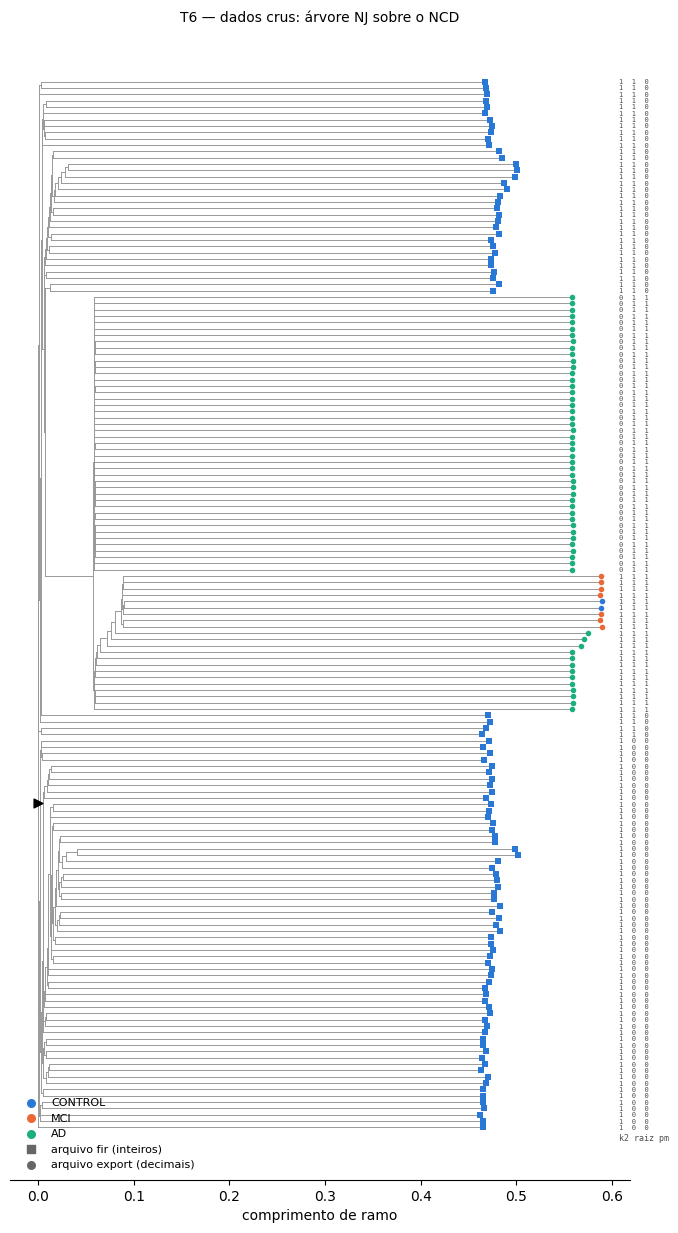

In [9]:
def layout_arvore(arvore):
    # Posições para desenhar a árvore a partir da raiz gravada (nj_root): x = distância da raiz, y = ordem das folhas.
    filhos, rot = {}, {n['id']: n.get('label') for n in arvore['nodes']}
    for e in arvore['edges']:
        filhos.setdefault(e['source'], []).append((e['target'], max(e['length'], 0.0)))
    x, y, prox = {'nj_root': 0.0}, {}, [0]
    def visita(n):
        if n not in filhos:
            y[n] = prox[0]; prox[0] += 1; return y[n]
        ys = []
        for f, L in filhos[n]:
            x[f] = x[n] + L; ys.append(visita(f))
        y[n] = (min(ys) + max(ys)) / 2
        return y[n]
    visita('nj_root')
    return filhos, rot, x, y

def desenhar_ramos(ax, filhos, x, y):
    for p, fs in filhos.items():
        ys = [y[f] for f, _ in fs]
        ax.plot([x[p], x[p]], [min(ys), max(ys)], color='0.6', lw=0.7)
        for f, _ in fs:
            ax.plot([x[p], x[f]], [y[f], y[f]], color='0.6', lw=0.7)
    ax.scatter(0, y['nj_root'], marker='>', color='black', s=40, zorder=4)

def desenhar_filograma(canal):
    filhos, rot, x, y = layout_arvore(arvores[canal])
    folhas = [n for n in x if n not in filhos]
    fig, ax = plt.subplots(figsize=(8, max(6, len(folhas) * 0.09)))
    desenhar_ramos(ax, filhos, x, y)
    xmax = max(x.values())
    for n in folhas:
        pid = pid_de(rot[n])
        ax.scatter(x[n], y[n], s=16, color=CORES[meta.loc[pid, 'grupo']], zorder=3, linewidths=0,
                   marker='s' if meta.loc[pid, 'formato'] == 'fir' else 'o')
        ax.text(xmax * 1.03, y[n], f"{etapa1['k2'][canal][pid]}  {etapa1['raiz_nj'][canal][pid]}  {etapa1['ponto_medio'][canal][pid]}",
                va='center', fontsize=5, color='0.3', family='monospace')
    ax.text(xmax * 1.03, -2, 'k2 raiz pm', fontsize=6, color='0.3', family='monospace')
    for g in ORDEM_GRUPOS:
        ax.scatter([], [], color=CORES[g], s=30, label=g)
    ax.scatter([], [], color='0.4', marker='s', s=30, label='arquivo fir (inteiros)')
    ax.scatter([], [], color='0.4', marker='o', s=30, label='arquivo export (decimais)')
    ax.legend(loc='lower left', frameon=False, fontsize=8)
    ax.set_title(f'{canal} — dados crus: árvore NJ sobre o NCD', fontsize=10)
    ax.set_yticks([]); ax.set_xlabel('comprimento de ramo')
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)
    return ax

(SAIDA / 'filogramas').mkdir(exist_ok=True)
for canal in CANAIS:
    ax = desenhar_filograma(canal)
    ax.figure.savefig(SAIDA / 'filogramas' / f'filograma_{canal}.png', dpi=150, bbox_inches='tight')
    plt.close(ax.figure)
desenhar_filograma(CANAL_EXEMPLO); plt.show()

## 6. Tabela discretizada (paciente × canal)

O cluster de cada paciente em cada canal é a discretização do canal. Uma tabela por forma de agrupar,
em `resultados_crus/tabela_discretizada_<metodo>.csv`. Valor `-1` = canal ausente (eletrodo plano).

Os números dos clusters são etiquetas sem significado: o "0" de um canal não corresponde ao "0" de outro.

In [10]:
ordem_pac = (meta.assign(_g=pd.Categorical(meta.grupo, ORDEM_GRUPOS, ordered=True))   # CONTROL, MCI, AD
                .sort_values(['_g', 'formato']).index)

def tabela_discretizada(metodo):
    return pd.DataFrame({c: etapa1[metodo][c].reindex(ordem_pac) for c in CANAIS}).fillna(-1).astype(int).rename_axis('paciente')

discretas = {mt: tabela_discretizada(mt) for mt in METODOS}
for mt, d in discretas.items():
    d.to_csv(SAIDA / f'tabela_discretizada_{mt}.csv')
discretas['k2'].head(8)

,Fp1,Fp2,F7,F3,Fz,F4,F8,T3,C3,Cz,C4,T4,T5,P3,Pz,P4,T6,O1,O2
paciente,,,,,,,,,,,,,,,,,,,
normal1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1
normal2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1
10057fir,1,1,1,0,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1
10188fir,1,1,1,0,1,1,0,1,1,0,1,1,0,0,1,1,1,1,1
10271fir,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
10600fir,1,1,1,0,1,1,1,1,1,0,1,1,0,0,1,1,1,1,1
1105fir,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
11066fir,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


## 7. Tabela de probabilidade

A partir da tabela discretizada escolhida em `FONTE_TABELA`:

1. **Tabela marginal:** para cada canal, a frequência de cada valor (cluster) entre os pacientes, P(canal = valor). Não usa o diagnóstico.
2. **Tabela de probabilidade transposta** (entrada da etapa 2): **linhas = canais, colunas = pacientes**. Cada célula é a probabilidade do valor
   que aquele paciente tem naquele canal. Exemplo: se no T6 o cluster 0 tem 104 dos 166 pacientes, um paciente no cluster 0 do T6 recebe `0.6265`.

Como a célula é a probabilidade do valor do paciente, a tabela não depende da numeração dos clusters: trocar 0 e 1 num canal não muda nada.
Um canal em que todos os valores têm a mesma frequência (ex.: 83/83) não informa nada, porque todos os pacientes recebem o mesmo número.

In [11]:
FONTE_TABELA = 'k2'      # 'auto', 'k2', 'raiz_nj' ou 'ponto_medio'
CASAS = 4                # casas decimais (o NCD compara texto: a formatação faz parte do objeto)

disc = discretas[FONTE_TABELA].replace(-1, np.nan)
marginal = pd.DataFrame([dict(canal=c, valor=int(v), n=int(n), P=n / disc[c].notna().sum())
                         for c in CANAIS for v, n in disc[c].dropna().astype(int).value_counts().sort_index().items()])
marginal.to_csv(SAIDA / f'tabela_marginal_{FONTE_TABELA}.csv', index=False)
print(f'Tabela marginal (discretização "{FONTE_TABELA}"): P(canal = valor)')
marginal.pivot(index='canal', columns='valor', values='P').loc[CANAIS].round(4)

Tabela marginal (discretização "k2"): P(canal = valor)


valor,0,1
canal,,
Fp1,0.3434,0.6566
Fp2,0.3976,0.6024
F7,0.3976,0.6024
F3,0.8012,0.1988
Fz,0.3976,0.6024
F4,0.3373,0.6627
F8,0.4578,0.5422
T3,0.3976,0.6024
C3,0.3976,0.6024


In [12]:
P = marginal.set_index(['canal', 'valor']).P
prob = pd.DataFrame({c: [P[(c, int(v))] if pd.notna(v) else np.nan for v in disc[c]] for c in CANAIS}, index=disc.index).T
tabela_prob = prob.map(lambda p: 'NA' if pd.isna(p) else f'{p:.{CASAS}f}')
tabela_prob.to_csv(SAIDA / f'tabela_probabilidade_{FONTE_TABELA}.csv', index=False)     # sem coluna de rótulo: toda coluna é um paciente
print(f'Tabela de probabilidade transposta: {tabela_prob.shape[0]} canais × {tabela_prob.shape[1]} pacientes '
      f'(arquivo tabela_probabilidade_{FONTE_TABELA}.csv). Amostra com 4 pacientes de cada grupo:')
mostra = [p for g in ORDEM_GRUPOS for p in meta.index[meta.grupo == g][:4]]
tabela_prob[mostra].set_axis(pd.MultiIndex.from_arrays([meta.loc[mostra, 'grupo'], mostra]), axis=1)

Tabela de probabilidade transposta: 19 canais × 166 pacientes (arquivo tabela_probabilidade_k2.csv). Amostra com 4 pacientes de cada grupo:


grupo  CONTROL                                MCI                              AD                        
      10057fir 10188fir 10271fir 10600fir    MCI1    MCI2    MCI3    MCI4     AD1     AD2     AD3     AD4
Fp1     0.6566   0.6566   0.6566   0.6566  0.3434  0.3434  0.3434  0.3434  0.3434  0.3434  0.3434  0.3434
Fp2     0.6024   0.6024   0.6024   0.6024  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976
F7      0.6024   0.6024   0.6024   0.6024  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976
F3      0.8012   0.8012   0.8012   0.8012  0.8012  0.8012  0.8012  0.8012  0.8012  0.8012  0.8012  0.1988
Fz      0.6024   0.6024   0.6024   0.6024  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976
F4      0.6627   0.6627   0.6627   0.6627  0.3373  0.3373  0.3373  0.3373  0.3373  0.3373  0.3373  0.3373
F8      0.4578   0.4578   0.5422   0.5422  0.4578  0.4578  0.4578  0.4578  0.4578  0.4578  0.4578  0.4578
T3      0.6024   0.6024   0.6024   0.6024  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976
C3      0.6024   0.6024   0.6024   0.6024  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976
Cz      0.4024   0.5976   0.4024   0.5976  0.5976  0.5976  0.5976  0.5976  0.5976  0.5976  0.5976  0.5976
C4      0.7289   0.7289   0.7289   0.7289  0.2711  0.2711  0.2711  0.2711  0.2711  0.2711  0.2711  0.2711
T4      0.5422   0.5422   0.5422   0.5422  0.4578  0.4578  0.4578  0.4578  0.4578  0.4578  0.4578  0.4578
T5      0.6145   0.6145   0.3855   0.6145  0.6145  0.6145  0.6145  0.6145  0.6145  0.6145  0.6145  0.6145
P3      0.6928   0.6928   0.3072   0.6928  0.6928  0.6928  0.6928  0.6928  0.6928  0.6928  0.6928  0.6928
Pz      0.5843   0.5843   0.5843   0.5843  0.4157  0.4157  0.4157  0.4157  0.4157  0.4157  0.4157  0.4157
P4      0.6024   0.6024   0.6024   0.6024  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976
T6      0.7349   0.7349   0.7349   0.7349  0.7349  0.7349  0.7349  0.7349  0.2651  0.7349  0.7349  0.2651
O1      0.6024   0.6024   0.6024   0.6024  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976  0.3976
O2      0.7590   0.7590   0.7590   0.7590  0.7590  0.7590  0.7590  0.7590  0.2410  0.7590  0.7590  0.2410

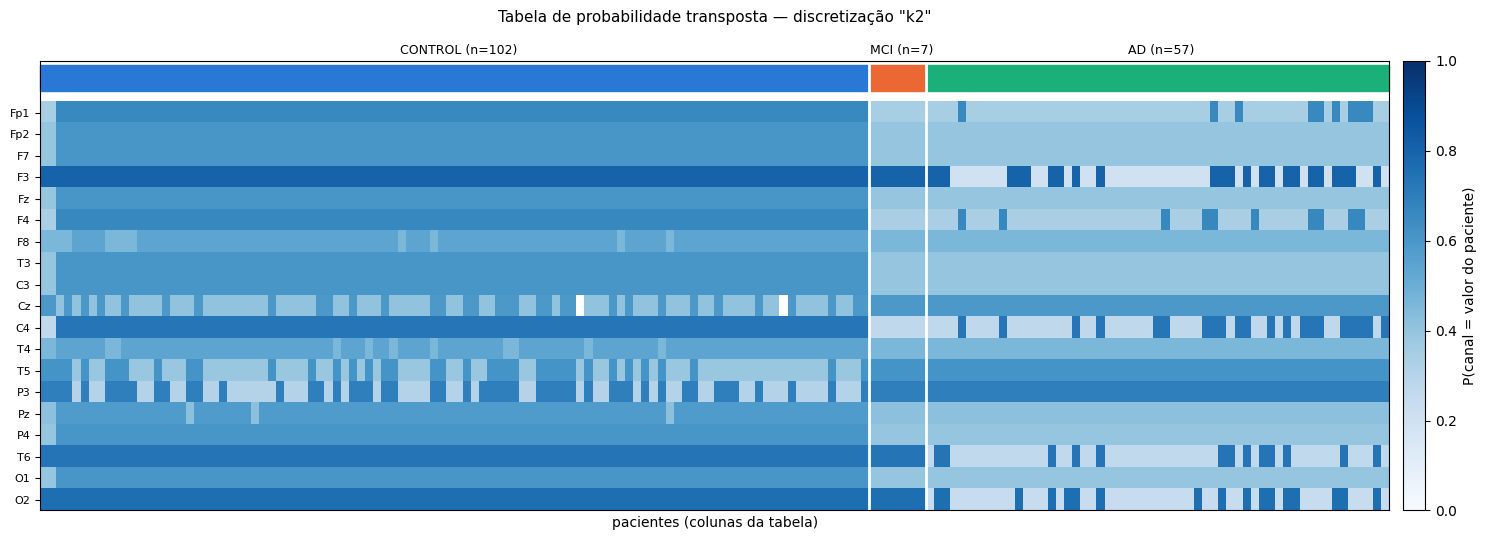

In [13]:
# A tabela inteira em uma figura: colunas = pacientes (ordenados por diagnóstico), linhas = canais, cor = probabilidade
fig, ax = plt.subplots(figsize=(15, 5.5))
im = ax.imshow(prob.to_numpy(dtype=float), aspect='auto', cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
ax.set_yticks(range(len(CANAIS)), CANAIS, fontsize=8)
ax.set_xticks([])
inicio = 0
for g in ORDEM_GRUPOS:
    n = int((meta.loc[prob.columns, 'grupo'] == g).sum())
    ax.add_patch(plt.Rectangle((inicio - 0.5, -2.2), n, 1.2, color=CORES[g], clip_on=False))
    ax.text(inicio + n / 2, -2.6, f'{g} (n={n})', ha='center', va='bottom', fontsize=9)
    if inicio:
        ax.axvline(inicio - 0.5, color='white', lw=2)
    inicio += n
ax.set_ylim(len(CANAIS) - 0.5, -2.4)
ax.set_xlabel('pacientes (colunas da tabela)')
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label='P(canal = valor do paciente)')
ax.set_title(f'Tabela de probabilidade transposta — discretização "{FONTE_TABELA}"', fontsize=11, pad=28)
plt.tight_layout(); plt.savefig(SAIDA / f'tabela_probabilidade_{FONTE_TABELA}.png', dpi=150); plt.show()

## 8. Etapa 2 — DAMICORE entre os pacientes

A tabela de probabilidade é passada ao DAMICORE com `split='columns'`: cada coluna (paciente) é um objeto. O resultado é o grupo de cada paciente,
que só no fim é comparado com o diagnóstico.

Pacientes com colunas idênticas têm NCD = 0, e isso pode quebrar a árvore (`Branch length is zero`). Nesse caso, as colunas idênticas são
juntadas num único **perfil**, o DAMICORE roda sobre os perfis e o grupo do perfil volta para cada paciente.

In [14]:
def etapa2(k):
    destino = SAIDA / 'etapa2' / f'{FONTE_TABELA}__k{k if k is not None else "auto"}'
    destino.mkdir(parents=True, exist_ok=True)
    tabela_prob.to_csv(destino / 'tabela_probabilidade.csv', index=False)
    chave = tabela_prob.T.apply(tuple, axis=1)
    ids = {}
    for kk in chave:
        ids.setdefault(kk, f'perfil_{len(ids) + 1:03d}')
    perfil = chave.map(ids)
    unicos = tabela_prob.loc[:, ~chave.duplicated().to_numpy()]
    unicos.columns = perfil[unicos.columns].to_numpy()
    unicos.to_csv(destino / 'tabela_perfis.csv', index=False)

    def executar(arquivo, pasta):
        args = dict(split='columns', num_clusters=k, output_dir=destino / pasta, progress=False,
                    execution=ExecutionConfig(workers='auto'))
        try:
            r = run(arquivo, **args)
        except OutputDirectoryConflictError:
            shutil.rmtree(destino / pasta); r = run(arquivo, **args)
        s = pd.Series(r.membership['cluster'].values, index=r.membership['label'].values)
        arvore = json.loads(r.artifacts.tree_json.read_text()); r.close()
        return s, arvore
    try:
        grupo, arvore = executar(destino / 'tabela_probabilidade.csv', 'damicore_pacientes')
        usar_perfis, objetos = False, 'pacientes'
    except TreeFormatError:
        grupo_perfil, arvore = executar(destino / 'tabela_perfis.csv', 'damicore_perfis')
        grupo = perfil.map(grupo_perfil)
        usar_perfis, objetos = True, f'{unicos.shape[1]} perfis (pacientes idênticos juntados)'

    res = meta.loc[tabela_prob.columns, ['grupo', 'formato', 'equipamento', 'escore_total']].copy()
    res.insert(0, 'cluster', grupo[res.index].to_numpy())
    res.to_csv(destino / 'resultado_pacientes.csv')
    print(f'k = {k if k is not None else "automático"} | objetos do DAMICORE: {objetos} | {res.cluster.nunique()} grupos')
    tab = pd.crosstab(res.grupo + ' | ' + res.formato, res.cluster)
    tab.to_csv(destino / 'cluster_x_diagnostico.csv')
    display(tab)
    display(pd.DataFrame([avaliar(res.cluster)]).round(3))
    return dict(k=k, destino=destino, resultado=res, arvore=arvore, usar_perfis=usar_perfis, perfil=perfil)

resultado_k2 = etapa2(2)

k = 2 | objetos do DAMICORE: pacientes | 2 grupos


cluster,0,1
row_0,,
AD | export,50,7
CONTROL | export,2,0
CONTROL | fir,0,100
MCI | export,7,0


,n_grupos,NMI_grupo,NMI_formato,NMI_grupo_export
0,2,0.639,0.781,0.041


In [15]:
resultado_auto = etapa2(None)

k = automático | objetos do DAMICORE: pacientes | 22 grupos


cluster,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
row_0,,,,,,,,,,,,,,,,,,,,,
AD | export,0,0,0,0,0,0,0,0,0,0,...,0,0,6,2,9,6,5,13,7,9
CONTROL | export,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CONTROL | fir,0,5,8,6,6,10,6,8,6,10,...,11,8,0,0,0,0,0,0,0,0
MCI | export,5,0,0,0,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,0,0


,n_grupos,NMI_grupo,NMI_formato,NMI_grupo_export
0,22,0.389,0.362,0.262


### 8.1 Filogramas da etapa 2

A árvore que o DAMICORE montou na segunda rodada, uma folha por paciente, para k=2 e para o automático:

- **ponto** = paciente; cor = diagnóstico; quadrado = arquivo `fir` (inteiros), círculo = `export` (decimais);
- **faixas** = os grupos do FastGreedy, com o número do grupo à direita;
- **à direita**, a composição de cada grupo por diagnóstico e formato do arquivo.

Se o DAMICORE precisou juntar pacientes idênticos em perfis, cada folha é um perfil e o tamanho do ponto indica quantos pacientes ele tem.
As figuras ficam em `resultados_crus/etapa2/<fonte>__k<k>/filograma_etapa2.png`.

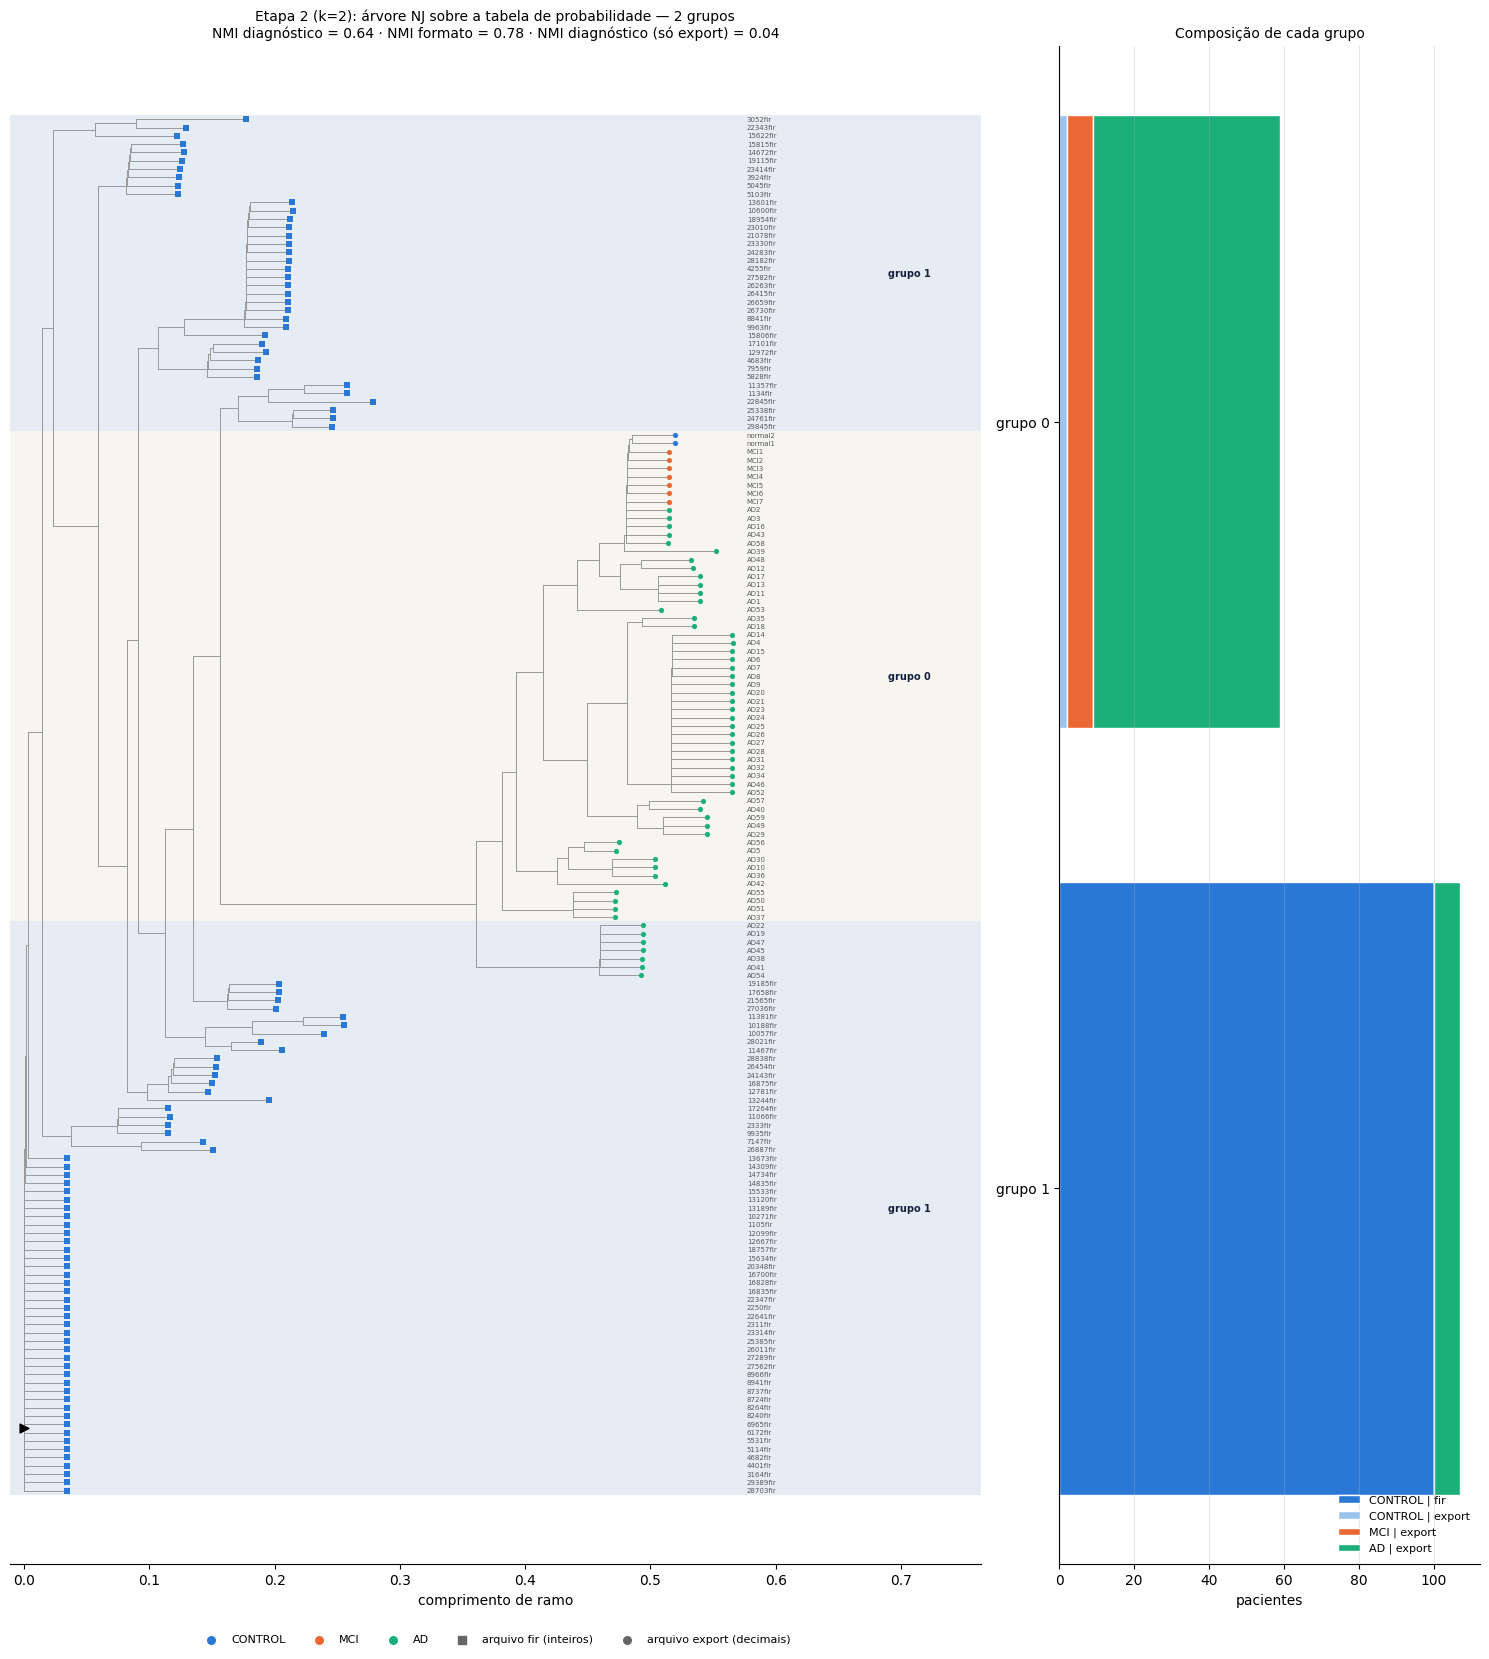

In [16]:
CATEGORIAS = ['CONTROL | fir', 'CONTROL | export', 'MCI | export', 'AD | export']
CORES_CAT = {'CONTROL | fir': '#2a78d6', 'CONTROL | export': '#9CC3EE', 'MCI | export': '#eb6834', 'AD | export': '#1baf7a'}

def desenhar_etapa2(saida):
    res, perfil = saida['resultado'], saida['perfil']
    filhos, rot, x, y = layout_arvore(saida['arvore'])
    folhas = sorted((n for n in x if n not in filhos), key=y.get)
    pacientes = {n: (list(perfil.index[perfil == rot[n]]) if saida['usar_perfis'] else [rot[n]]) for n in folhas}
    cluster = {n: res.loc[pacientes[n][0], 'cluster'] for n in folhas}

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, max(7, len(folhas) * 0.1)),
                                  gridspec_kw=dict(width_ratios=[3, 1.3]))
    xmax = max(x.values())
    # faixas dos grupos: trechos seguidos de folhas no mesmo grupo
    trechos = []
    for n in folhas:
        if trechos and trechos[-1][0] == cluster[n]:
            trechos[-1][2] = y[n]
        else:
            trechos.append([cluster[n], y[n], y[n]])
    for i, (c, a, b) in enumerate(trechos):
        ax.axhspan(a - 0.5, b + 0.5, color='#E6ECF4' if i % 2 == 0 else '#F6F5F0', zorder=0, lw=0)
        ax.text(xmax * 1.22, (a + b) / 2, f'grupo {c}', va='center', fontsize=7, fontweight='bold', color='#14213D')
    desenhar_ramos(ax, filhos, x, y)
    for n in folhas:
        m = res.loc[pacientes[n]]
        grupo, formato = m.grupo.mode()[0], m.formato.mode()[0]
        ax.scatter(x[n], y[n], s=14 + 8 * (len(m) - 1), color=CORES[grupo], zorder=3, linewidths=0,
                   marker='s' if formato == 'fir' else 'o')
        nome = pacientes[n][0] if len(m) == 1 else f'{rot[n]} (n={len(m)})'
        ax.text(xmax * 1.02, y[n], nome, va='center', fontsize=5, color='0.35')
    for g in ORDEM_GRUPOS:
        ax.scatter([], [], color=CORES[g], s=30, label=g)
    ax.scatter([], [], color='0.4', marker='s', s=30, label='arquivo fir (inteiros)')
    ax.scatter([], [], color='0.4', marker='o', s=30, label='arquivo export (decimais)')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.04), ncol=5, frameon=False, fontsize=8)
    av = avaliar(res.cluster)
    rotulo_k = 'automático' if saida['k'] is None else f"k={saida['k']}"
    ax.set_title(f"Etapa 2 ({rotulo_k}): árvore NJ sobre a tabela de probabilidade — {av['n_grupos']} grupos\n"
                 f"NMI diagnóstico = {av['NMI_grupo']:.2f} · NMI formato = {av['NMI_formato']:.2f} · "
                 f"NMI diagnóstico (só export) = {av['NMI_grupo_export']:.2f}", fontsize=10)
    ax.set_yticks([]); ax.set_xlabel('comprimento de ramo')
    ax.set_xlim(-xmax * 0.02, xmax * 1.35)
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)

    comp = pd.crosstab(res.cluster, res.grupo + ' | ' + res.formato).reindex(columns=CATEGORIAS, fill_value=0)
    esquerda = np.zeros(len(comp))
    for cat in CATEGORIAS:
        ax2.barh([f'grupo {c}' for c in comp.index], comp[cat], left=esquerda, color=CORES_CAT[cat],
                 edgecolor='white', linewidth=1, label=cat)
        esquerda += comp[cat].to_numpy()
    ax2.invert_yaxis()
    ax2.set_xlabel('pacientes'); ax2.set_title('Composição de cada grupo', fontsize=10)
    ax2.legend(frameon=False, fontsize=8, loc='lower right')
    ax2.grid(axis='x', alpha=.3)
    for s in ['top', 'right']:
        ax2.spines[s].set_visible(False)
    plt.tight_layout()
    plt.savefig(saida['destino'] / 'filograma_etapa2.png', dpi=150, bbox_inches='tight')
    plt.show()

desenhar_etapa2(resultado_k2)

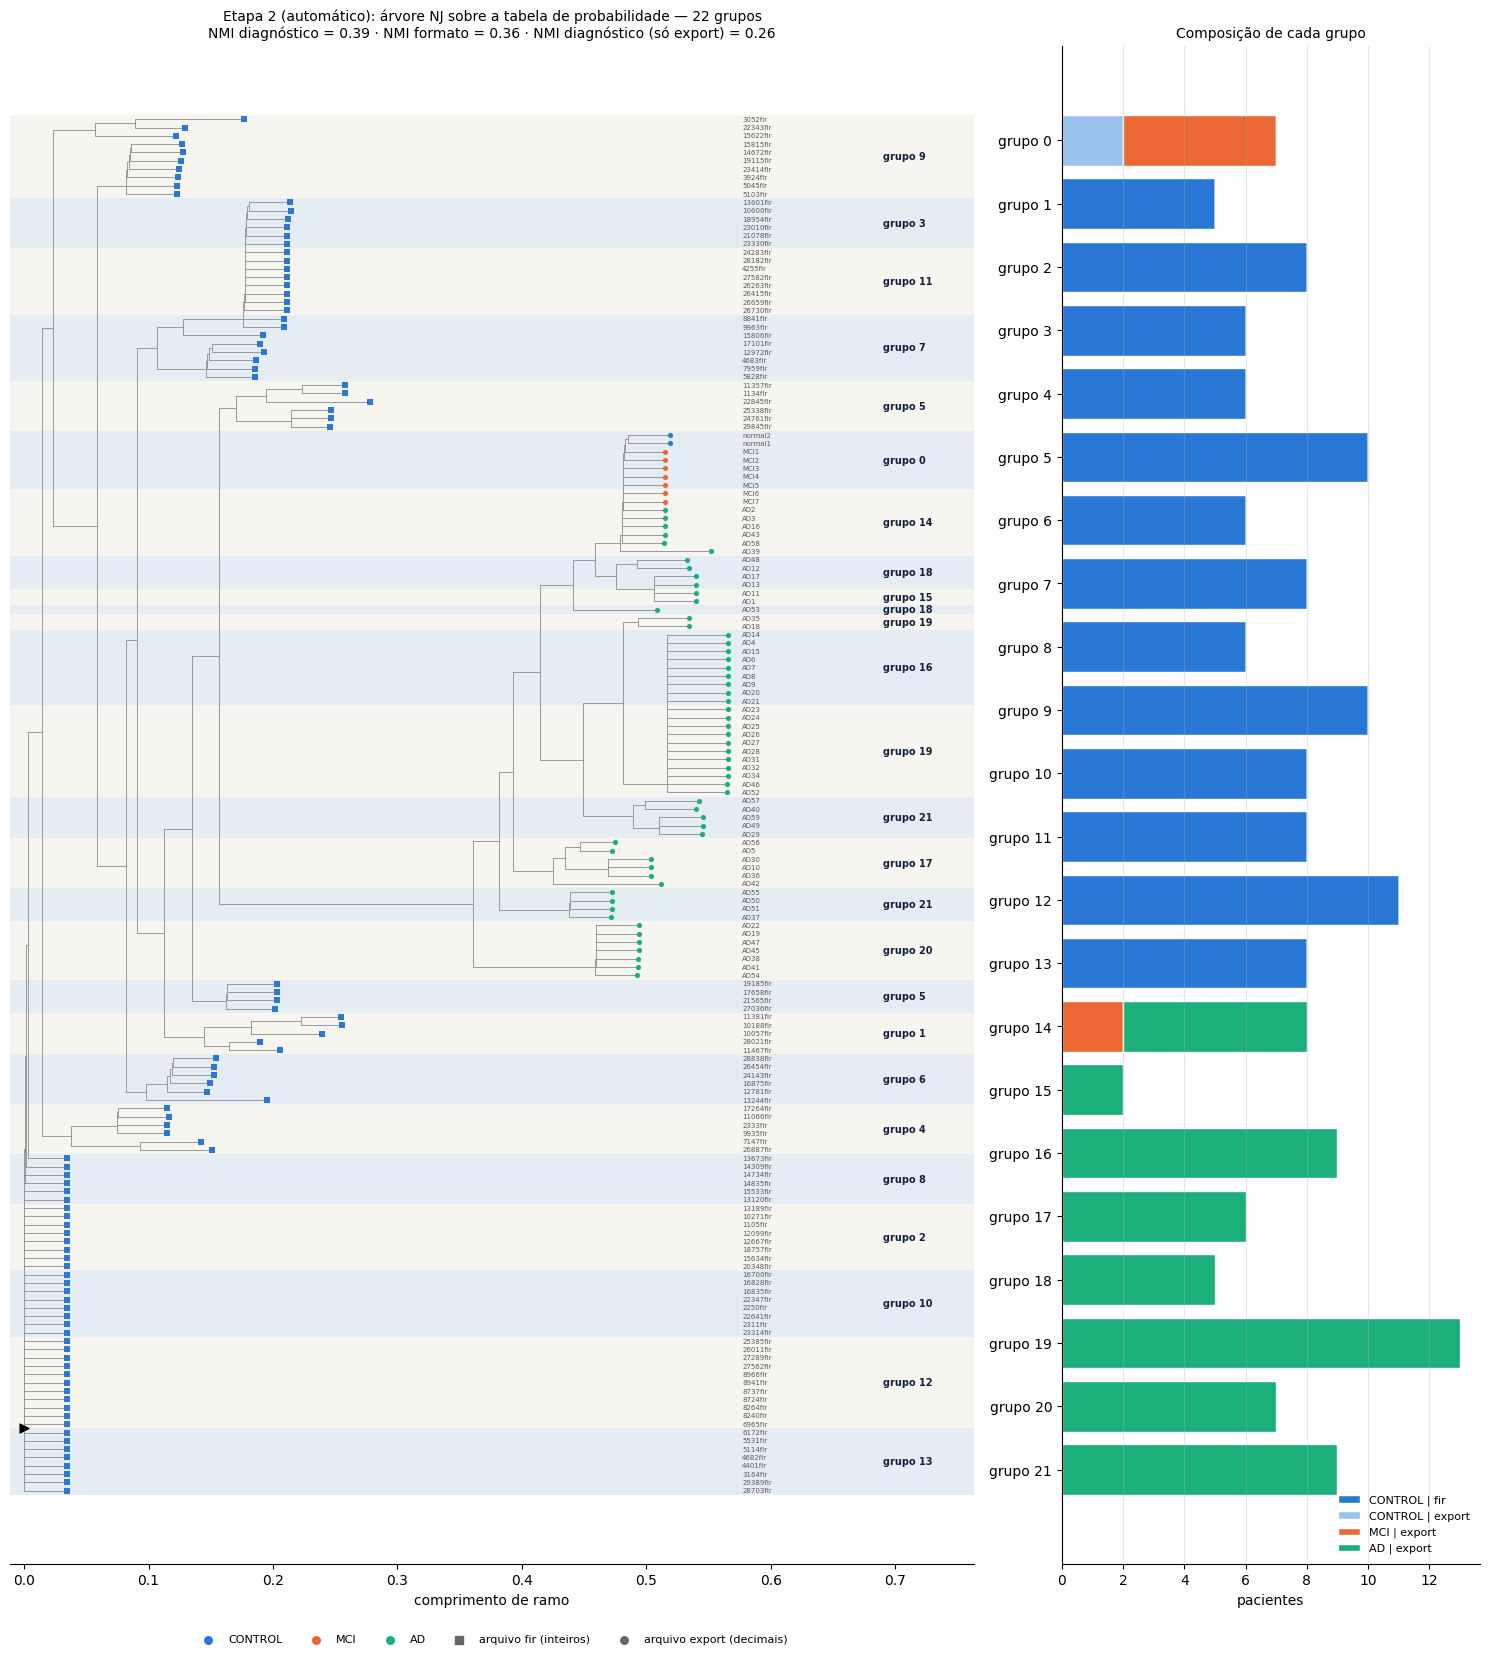

In [17]:
desenhar_etapa2(resultado_auto)

## 9. Arquivos gerados (`resultados_crus/`)

| Arquivo | Conteúdo |
|---|---|
| `pacientes.csv` | inventário: diagnóstico, formato do arquivo, aparelho, escore |
| `canais/<canal>/` | os objetos da etapa 1 (valores originais) |
| `damicore/auto/<canal>/`, `damicore/k2/<canal>/` | artefatos das duas execuções do DAMICORE por canal |
| `comparacao_cortes_em_dois.csv` | k=2 × raiz do NJ × ponto médio |
| `avaliacao_etapa1.csv` | NMI com diagnóstico e formato, por método e canal |
| `filogramas/` | um filograma por canal |
| `tabela_discretizada_<metodo>.csv` | paciente × canal |
| `tabela_marginal_<fonte>.csv`, `tabela_probabilidade_<fonte>.csv/.png` | tabela marginal e tabela transposta (canais × pacientes) |
| `etapa2/<fonte>__k<k>/` | entrada, artefatos, resultado do DAMICORE entre pacientes e `filograma_etapa2.png` |